# Chapter 31: How Much Has Accumulated?

*Math Class Didn't Show Its Work* by Jason Karpeles

**In this notebook you will** turn a rate into a running total. We start with two blocks of constant rate, learn why a block below the baseline subtracts, then build rectangle sums for a changing rate, first with equal widths and then with unequal ones. The gauge reports the rate; the running total keeps the receipts.

The code cells are optional reading. Every result and every picture is shown right below the cell that makes it, so you can follow along without running anything. If you do want to run a cell, change a number and see what happens: nothing here can break.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

NAVY, TEAL, GOLD, PINK, INK, GREY = "#1f3a5f", "#1b8a8a", "#d9a21b", "#c0467a", "#222222", "#888888"

def g(x, digits=4):
    """Format a number without trailing zeros."""
    s = f"{x:.{digits}f}".rstrip("0").rstrip(".")
    return "0" if s in ("-0", "") else s

def par(x):
    """Wrap negative numbers in parentheses, for substitution chains."""
    s = g(x)
    return f"({s})" if s.startswith("-") else s

def new_fig(w=7, h=4):
    fig, ax = plt.subplots(figsize=(w, h))
    ax.grid(alpha=0.25)
    return fig, ax

## Demonstration 1: Rate times duration, block by block

**Question.** What does a block below the baseline do to the running total?

$$6 + (-1) = 5\ \text{units} \qquad\qquad 10 + 5 = 15\ \text{units}$$

- A rate is in units per hour and a width is in hours, so each rectangle's height times its width is a change in units.
- The starting amount is 10 units.
- Block 1: rate 3 units per hour for 2 hours. Block 2: rate $-1$ unit per hour for 1 hour.

**Predict first:** make the second rate $-3$ instead of $-1$. Where does the running total end?

Starting values: second rate $-1$.

In [2]:
r1, w1 = 3, 2
r2, w2 = -1, 1
start = 10
c1, c2 = r1*w1, r2*w2
net = c1 + c2
print(f"First change:  {r1} x {w1} = {c1} units")
print(f"Second change: {par(r2)} x {w2} = {c2} unit")
print(f"Net change: {c1} + {par(c2)} = {net} units")
print(f"Ending amount: {start} + {net} = {start + net} units")
print()
print("Other menu values for the second rate (width stays 1 hour):")
for rr in (-3, -1, 0, 1):
    n = c1 + rr*1
    print(f"  rate {par(rr):>4}: net {c1} + {par(rr*1)} = {n}, ending {start} + {n} = {start + n}")

First change:  3 x 2 = 6 units
Second change: (-1) x 1 = -1 unit
Net change: 6 + (-1) = 5 units
Ending amount: 10 + 5 = 15 units

Other menu values for the second rate (width stays 1 hour):
  rate (-3): net 6 + (-3) = 3, ending 10 + 3 = 13
  rate (-1): net 6 + (-1) = 5, ending 10 + 5 = 15
  rate    0: net 6 + 0 = 6, ending 10 + 6 = 16
  rate    1: net 6 + 1 = 7, ending 10 + 7 = 17


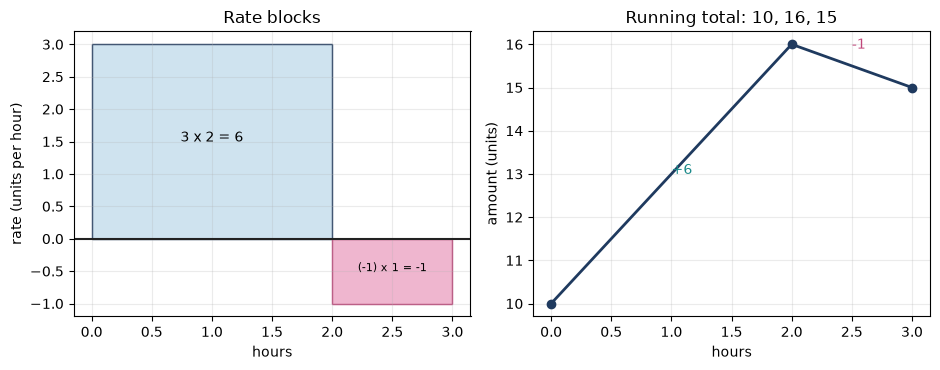

In [3]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.5, 3.8))
a1.bar([1], [3], width=2, fc="#cfe3ef", ec=NAVY, align="center")
a1.bar([2.5], [-1], width=1, fc="#efb6cf", ec=PINK, align="center")
a1.axhline(0, color=INK)
a1.text(1, 1.5, "3 x 2 = 6", ha="center"); a1.text(2.5, -0.5, "(-1) x 1 = -1", ha="center", fontsize=8)
a1.set_xlabel("hours"); a1.set_ylabel("rate (units per hour)"); a1.set_title("Rate blocks"); a1.grid(alpha=0.25)
a2.plot([0, 2, 3], [10, 16, 15], "o-", color=NAVY, lw=2)
a2.annotate("+6", (1, 13), color=TEAL); a2.annotate("-1", (2.5, 15.9), color=PINK)
a2.set_xlabel("hours"); a2.set_ylabel("amount (units)"); a2.set_title("Running total: 10, 16, 15"); a2.grid(alpha=0.25)
plt.tight_layout(); plt.show()

**What this shows.** Each block contributes height times width, keeping its sign. The block below the baseline pulls the running total down. Before adding a rate to an amount, multiply it by a duration: a rate and an amount have different units and cannot be added directly.

**Where it stops working.** The rate is declared constant on each block, which is what makes each rectangle exact. If the rate varied inside a block, one rectangle would only be an estimate.

## Demonstration 2: Net change or total magnitude?

**Question.** The same two pieces, $+6$ and $-1$, give 5 or 7. Which one answers your question?

$$6 - 1 = 5 \qquad\qquad 6 + 1 = 7$$

- $+6$ is the contribution above the baseline. The second piece lies below it.
- Net change keeps the signs. Total magnitude adds the sizes without their signs.

**Predict first:** keep the question on net change and make the second piece $-6$. What is the net change?

Starting values: second piece $-1$, question on net change.

In [4]:
a, b = 6, -1
print(f"Net change (signs kept): {a} - {abs(b)} = {a + b} units")
print(f"Total magnitude (signs dropped): {a} + {abs(b)} = {a + abs(b)} units")
print(f"Answer to a net-change question: {a + b} units")
print()
print("Other menu values:")
for bb in (-1, -3, -6):
    print(f"  pieces +6 and {bb}: net 6 - {abs(bb)} = {6 + bb}; magnitude 6 + {abs(bb)} = {6 + abs(bb)}")

Net change (signs kept): 6 - 1 = 5 units
Total magnitude (signs dropped): 6 + 1 = 7 units
Answer to a net-change question: 5 units

Other menu values:
  pieces +6 and -1: net 6 - 1 = 5; magnitude 6 + 1 = 7
  pieces +6 and -3: net 6 - 3 = 3; magnitude 6 + 3 = 9
  pieces +6 and -6: net 6 - 6 = 0; magnitude 6 + 6 = 12


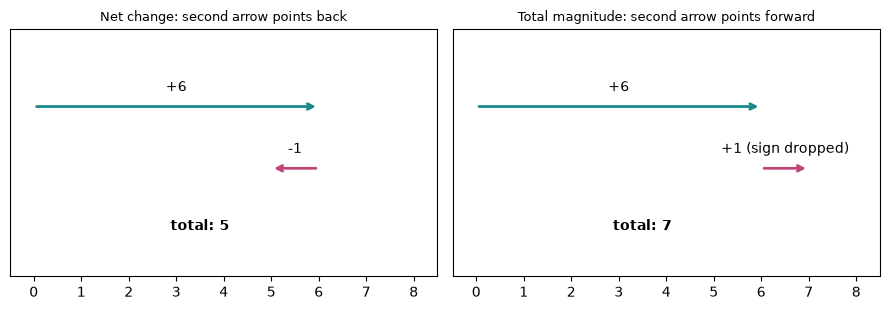

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.2), sharex=True)
for ax, title, second in ((a1, "Net change: second arrow points back", -1), (a2, "Total magnitude: second arrow points forward", +1)):
    ax.annotate("", xy=(6, 0.6), xytext=(0, 0.6), arrowprops=dict(arrowstyle="->", color=TEAL, lw=2))
    ax.annotate("", xy=(6 + second, 0.2), xytext=(6, 0.2), arrowprops=dict(arrowstyle="->", color=PINK, lw=2))
    ax.text(3, 0.7, "+6", ha="center"); ax.text(6 + second/2, 0.3, f"{'-1' if second < 0 else '+1 (sign dropped)'}", ha="center")
    ax.text(3.5, -0.2, f"total: {6 + second}", ha="center", fontweight="bold")
    ax.set_xlim(-0.5, 8.5); ax.set_ylim(-0.5, 1.1); ax.set_yticks([]); ax.set_title(title, fontsize=9)
plt.tight_layout(); plt.show()

**What this shows.** For net change the second arrow points back; for total magnitude it points forward, because the sign has been dropped on purpose. Both numbers are correct answers to different questions. Decide first whether you want where things ended up (net) or how much happened in all (magnitude).

**Where it stops working.** Large pieces of opposite sign can nearly cancel, so a small net change can hide a lot of activity.

## Demonstration 3: Where you sample matters

**Question.** For the rising rate $r(t) = t$, why do left and right rectangles disagree?

$$r(t) = t \qquad\qquad \text{sum of } r(t_i^*)\,\Delta t_i$$

- $r(t)$ is the rate in units per hour at time $t$, from 0 to 2 hours.
- $t_i^*$ is the sample time chosen in piece $i$, and $\Delta t_i$ is that piece's width in hours.

**Predict first:** with 2 rectangles, which rule gives 1, which gives 2, and which gives 3?

Starting values: midpoint rule, 2 rectangles.

In [6]:
def sample_sum(rule, n, a=0, b=2, r=lambda t: t):
    w = (b - a)/n
    edges = [a + i*w for i in range(n + 1)]
    pts = [{"left": e, "right": e + w, "mid": e + w/2}[rule] for e in edges[:-1]]
    return w, pts, [r(p) for p in pts]

w, pts, hs = sample_sum("mid", 2)
print(f"Rectangles: 2, each {g(w)} hour wide")
print(f"Sample heights r({g(pts[0])}) and r({g(pts[1])}): {g(hs[0])} and {g(hs[1])}")
print(f"Estimate: {g(w)} x {g(hs[0])} + {g(w)} x {g(hs[1])} = {g(w*hs[0])} + {g(w*hs[1])} = {g(w*sum(hs))} units")
print(f"Triangle under the line: 2 x 2 / 2 = 2 units")
print()
print("All six menu states:")
for n in (2, 4):
    for rule in ("left", "mid", "right"):
        w, pts, hs = sample_sum(rule, n)
        terms = " + ".join(g(h) for h in hs)
        print(f"  n = {n}, {rule:>5}: heights {terms}; estimate {g(w)} x ({terms}) = {g(w*sum(hs))}")

Rectangles: 2, each 1 hour wide
Sample heights r(0.5) and r(1.5): 0.5 and 1.5
Estimate: 1 x 0.5 + 1 x 1.5 = 0.5 + 1.5 = 2 units
Triangle under the line: 2 x 2 / 2 = 2 units

All six menu states:
  n = 2,  left: heights 0 + 1; estimate 1 x (0 + 1) = 1
  n = 2,   mid: heights 0.5 + 1.5; estimate 1 x (0.5 + 1.5) = 2
  n = 2, right: heights 1 + 2; estimate 1 x (1 + 2) = 3
  n = 4,  left: heights 0 + 0.5 + 1 + 1.5; estimate 0.5 x (0 + 0.5 + 1 + 1.5) = 1.5
  n = 4,   mid: heights 0.25 + 0.75 + 1.25 + 1.75; estimate 0.5 x (0.25 + 0.75 + 1.25 + 1.75) = 2
  n = 4, right: heights 0.5 + 1 + 1.5 + 2; estimate 0.5 x (0.5 + 1 + 1.5 + 2) = 2.5


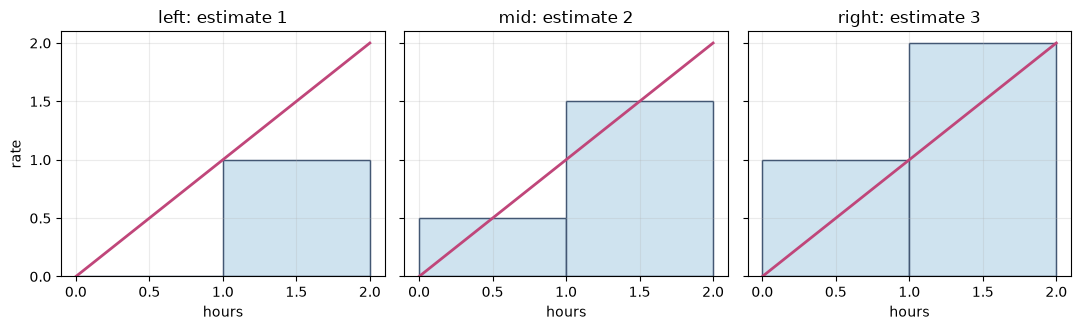

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
ts = np.linspace(0, 2, 50)
for ax, rule in zip(axes, ("left", "mid", "right")):
    w, pts, hs = sample_sum(rule, 2)
    for i, h in enumerate(hs):
        ax.bar(i*w, h, width=w, align="edge", fc="#cfe3ef", ec=NAVY)
    ax.plot(ts, ts, color=PINK, lw=2)
    ax.set_title(f"{rule}: estimate {g(w*sum(hs))}"); ax.grid(alpha=0.25); ax.set_xlabel("hours")
axes[0].set_ylabel("rate")
plt.tight_layout(); plt.show()

**What this shows.** Each rectangle's height is the rate at its sample time. On a rising line, left samples sit low and right samples sit high; the midpoint lands exactly on the true area of 2 for a straight line. More rectangles shrink the gap (with 4 rectangles: 1.5, 2 and 2.5). When you estimate a total from samples, say both the partition and the sampling rule.

**Where it stops working.** The left-low, right-high pattern needs an increasing rate. A falling or wavy rate can order the estimates differently.

## Demonstration 4: Unequal widths, each in its own place

**Question.** When the pieces have different widths, what must each rate be multiplied by?

$$r(t) = 2t \qquad\qquad 2.5(0.5) + 4.5(1.5) = 1.25 + 6.75 = 8$$

- $r(t) = 2t$ is the rate in units per hour from 1 to 3 hours.
- The book partition 1, 1.5, 3 gives widths 0.5 and 1.5 hours.

**Predict first:** switch the book partition to left endpoints. Will the sum be above or below 8?

Starting values: book partition, midpoint rule.

In [8]:
r = lambda t: 2*t
def usum(edges, rule):
    out = []
    for a, b in zip(edges[:-1], edges[1:]):
        t = {"left": a, "right": b, "mid": (a + b)/2}[rule]
        out.append((t, r(t), b - a))
    return out

parts = usum([1, 1.5, 3], "mid")
print("Partition 1, 1.5, 3: widths", " and ".join(g(w) for _, _, w in parts), "hours")
print("Sample rates:", " and ".join(g(h) for _, h, _ in parts))
terms = " + ".join(f"{g(h)}({g(w)})" for _, h, w in parts)
vals = " + ".join(g(h*w) for _, h, w in parts)
print(f"Midpoint sum: {terms} = {vals} = {g(sum(h*w for _, h, w in parts))} units")
print("Exact: average rate 4 x 2 hours = 8 units")
print()
for name, edges in (("book", [1, 1.5, 3]), ("even", [1, 2, 3])):
    for rule in ("left", "mid", "right"):
        p = usum(edges, rule)
        t = " + ".join(f"{g(h)}({g(w)})" for _, h, w in p)
        s = sum(h*w for _, h, w in p)
        print(f"  {name:>4}, {rule:>5}: {t} = {g(s)}  (off by {g(s - 8)})")

Partition 1, 1.5, 3: widths 0.5 and 1.5 hours
Sample rates: 2.5 and 4.5
Midpoint sum: 2.5(0.5) + 4.5(1.5) = 1.25 + 6.75 = 8 units
Exact: average rate 4 x 2 hours = 8 units

  book,  left: 2(0.5) + 3(1.5) = 5.5  (off by -2.5)
  book,   mid: 2.5(0.5) + 4.5(1.5) = 8  (off by 0)
  book, right: 3(0.5) + 6(1.5) = 10.5  (off by 2.5)
  even,  left: 2(1) + 4(1) = 6  (off by -2)
  even,   mid: 3(1) + 5(1) = 8  (off by 0)
  even, right: 4(1) + 6(1) = 10  (off by 2)


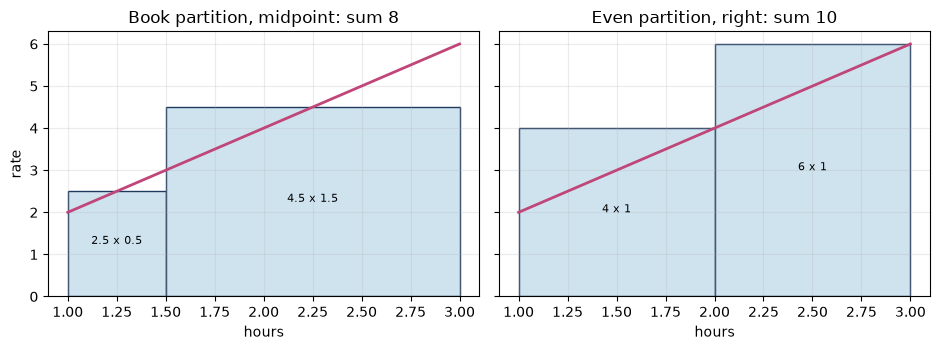

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6), sharey=True)
ts = np.linspace(1, 3, 50)
for ax, (name, edges, rule) in zip(axes, (("Book partition, midpoint", [1, 1.5, 3], "mid"), ("Even partition, right", [1, 2, 3], "right"))):
    for t, h, w in usum(edges, rule):
        ax.bar(t - (w/2 if rule == "mid" else (w if rule == "right" else 0)), h, width=w, align="edge", fc="#cfe3ef", ec=NAVY)
        ax.text(t - (w/2 if rule == "mid" else w) + w/2, h/2, f"{g(h)} x {g(w)}", ha="center", fontsize=8)
    ax.plot(ts, 2*ts, color=PINK, lw=2)
    ax.set_title(f"{name}: sum {g(sum(h*w for _, h, w in usum(edges, rule)))}"); ax.grid(alpha=0.25); ax.set_xlabel("hours")
axes[0].set_ylabel("rate")
plt.tight_layout(); plt.show()

**What this shows.** Each rectangle is labelled rate times width. The widths differ, so there is no single width to factor out: every rate keeps its own. The midpoint sum matches the exact 8 because each midpoint rectangle equals its trapezoid for a straight line. Data often comes at uneven spacing, so multiply each reading by its own interval before adding.

**Where it stops working.** The exact match depends on the straight-line rate. For a curved rate the same recipe is only an estimate.

## Practice

Try each one on paper first, then open the answer to compare.

**1.** If the second rate were $-2$ units per hour for 1 hour, what would the ending amount be (first block still 3 units per hour for 2 hours, start 10)?

<details><summary>Show answer</summary>

Net change: $6 + (-2) = 4$ units. Ending amount: $10 + 4 = 14$ units.

</details>

**2.** With pieces $+6$ and $-3$, what are the net change and the total magnitude?

<details><summary>Show answer</summary>

Net change: $6 - 3 = 3$ units. Total magnitude: $6 + 3 = 9$ units.

</details>

**3.** With 4 rectangles and right endpoints on $r(t) = t$ from 0 to 2, what are the heights and the estimate?

<details><summary>Show answer</summary>

Each width is $2/4 = 0.5$. Right endpoints are 0.5, 1, 1.5, 2, so the heights are 0.5, 1, 1.5, 2. Estimate: $0.5 \times (0.5 + 1 + 1.5 + 2) = 0.5 \times 5 = 2.5$ units.

</details>

**4.** On the even partition 1, 2, 3 with right endpoints for $r(t) = 2t$, what is the sum?

<details><summary>Show answer</summary>

Right endpoints are 2 and 3, so the rates are 4 and 6. Sum: $4(1) + 6(1) = 4 + 6 = 10$ units, which is 2 above the exact 8.

</details>